# Экзаменационная задача №12. Выбор стратегии защиты интеллектуальной собственности

**Дисциплина:** Экономика информатизации, лекция №13
**Студент:** Грошев Степан Сергеевич, группа БИ 5-1
**Дата:** 2026-11-12

In [1]:
# ======================================================================
# ЭКЗАМЕНАЦИОННАЯ ЗАДАЧА №12: ВЫБОР СТРАТЕГИИ ЗАЩИТЫ ИНТЕЛЛЕКТУАЛЬНОЙ СОБСТВЕННОСТИ
# ======================================================================
# Дисциплина: Экономика информатизации (лекция №13)
# Дата: 2026-11-12
# Студент: Грошев Степан Сергеевич
# Группа: БИ 5-1
# ======================================================================

# Подключение библиотек и общих утилит проекта
import sys, math
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # корень репозитория: utils/
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils.calculations import npv, irr, payback_period, discounted_payback_period, present_values, annuity_factor, fmt_rub
from utils.visualization import setup_style, thousands_axis, bar_labels, tornado, PALETTE
setup_style()
pd.set_option("display.float_format", lambda v: f"{v:,.2f}".replace(",", " "))
pd.set_option("display.width", 140)

## 1. Экономическая постановка задачи

Стартап в сфере AI-образования сделал алгоритм, который подбирает ученику учебную траекторию. Нужно выбрать,
как защищать интеллектуальную собственность (IP). От выбора зависят затраты (пошлины, юристы, риск судов),
скорость распространения продукта (сетевые эффекты, сообщество) и способы заработка.

**Цель:** оценить затраты и NPV разных стратегий защиты IP и выбрать лучшую с учётом рисков.

**Исходные данные** в условии вынесены в приложение, которого нет в материалах курса. Поэтому параметры взяты
для условного стартапа «УмныйКурс» по ориентирам лекции №13 (патент за весь срок $20–100 тыс., это 2–9 млн руб.;
патентный спор в США $4–8 млн, в РФ намного дешевле) и по типичным моделям заработка на open source
(open core, поддержка, обучение). Все допущения перечислены и проверены анализом чувствительности и методом Монте-Карло.

Тема лекции №13: экономика патентов (монопольная рента и мёртвые потери), коммерческая тайна, open source и open core,
патентные тролли, сетевые эффекты.

## 2. Исходные данные

In [2]:
H = 7            # горизонт, лет (срок морального устаревания алгоритма)
r = 0.18         # ставка дисконтирования для стартапа (высокий риск)

# 2.1. Стратегия «Патент» (РФ + международная заявка PCT на ключевой алгоритм)
patent = dict(search=0.6, filing=1.8, maintenance=0.4, litigation_cost=6.0, litigation_prob=0.25,
              licensing=2.5, licensing_from=3)      # млн руб.; роялти с 3-го года
# 2.2. Стратегия «Open source» (open core: ядро открыто, корпоративные функции платные)
oss = dict(community=2.5, rd_saving=0.20, rd_budget=8.0)  # затраты на комьюнити/год; экономия R&D за счёт контрибьюторов
# 2.3. Стратегия «Коммерческая тайна» (закрытый код, NDA, режим КТ)
secret = dict(setup=0.5, security=0.6, leak_prob=0.30, leak_year=4, leak_loss=0.35)   # вероятность утечки/копирования к 4-му году
# 2.4. Выручка по стратегиям, млн руб./год (годы 1..7)
#   Закрытые стратегии: медленнее рост (продажи школам напрямую), выше средний чек.
#   Open source: быстрый рост пользователей (сетевой эффект), монетизация 5–8% пользователей + поддержка/обучение.
revenue = pd.DataFrame({
    "Закрытый продукт": [4, 9, 16, 24, 30, 34, 36],
    "Open core":        [2, 7, 15, 26, 36, 43, 47],
}, index=pd.Index(range(1, H + 1), name="Год"))
cost_ratio = 0.45      # операционные затраты (без R&D и IP), доля выручки
revenue

,Закрытый продукт,Open core
Год,,
1,4,2
2,9,7
3,16,15
4,24,26
5,30,36
6,34,43
7,36,47


**Почему такие допущения:**
- Патент в РФ даёт исключительное право на 20 лет, но защищает только **техническое решение**, а не алгоритм как таковой.
  Есть риск отказа или обхода, поэтому закладываем вероятность спора 25 % стоимостью 6 млн руб.
- Open core первые 2 года растёт медленнее (заработок ещё не настроен), но к 4-му году обгоняет закрытый продукт
  за счёт бесплатного распространения и сообщества (сетевой эффект). Участники сообщества экономят около 20 % затрат на разработку.
- Коммерческая тайна дешевле всего, но не спасает, если конкуренты сделают то же самое сами или разберут продукт.
  С вероятностью 30 % к 4-му году решение повторят, и выручка упадёт на 35 %.

## 3. Математическая модель

Денежный поток стратегии $s$ в году $t$:
$$CF^s_t = R^s_t(1-c) - RD_t + L^s_t - C^{IP,s}_t,$$
где $R$ выручка, $c$ доля операционных затрат, $RD$ затраты на разработку (8 млн руб. в год, у open core меньше
на экономию от сообщества), $L$ роялти от лицензий, $C^{IP}$ затраты на защиту IP.
Риски учитываем через **ожидаемые значения**: $E[C_{спор}] = p\cdot C_{спор}$, $E[R^{тайна}_t] = R_t(1-p_{утечки}\cdot\delta)$ при $t\ge t_{утечки}$.
$$NPV^s=\sum_{t=0}^{7}\frac{CF^s_t}{(1+r)^t}$$
Разброс NPV получаем методом Монте-Карло (10 000 испытаний): меняем выручку (±25 %), вероятности рисков и экономию на разработке.

## 4. Реализация расчёта
### 4.1. Затраты на защиту IP по стратегиям

In [3]:
def ip_costs(strategy, p=patent, o=oss, s=secret):
    """Затраты на защиту IP по годам 0..H (млн руб., ожидаемые значения)."""
    c = np.zeros(H + 1)
    if strategy in ("Патент", "Гибрид"):
        c[0] += p["search"] + p["filing"]
        c[1:] += p["maintenance"]
        c[2] += p["litigation_prob"] * p["litigation_cost"]          # ожидаемая стоимость спора (наиболее вероятен на 2-м году)
    if strategy in ("Open source", "Гибрид"):
        c[1:] += o["community"]
    if strategy == "Коммерческая тайна":
        c[0] += s["setup"]; c[1:] += s["security"]
    return c

strategies = ["Патент", "Open source", "Коммерческая тайна", "Гибрид"]
costs_tbl = pd.DataFrame({st: ip_costs(st) for st in strategies}, index=pd.Index(range(H + 1), name="Год"))
summary_cost = pd.DataFrame({"Затраты на IP номинал, млн": costs_tbl.sum(), "Затраты на IP (PV), млн": [npv(costs_tbl[s].values, r) for s in strategies]})
display(costs_tbl.round(2))
summary_cost.round(2)

,Патент,Open source,Коммерческая тайна,Гибрид
Год,,,,
0,2.40,0.00,0.50,2.40
1,0.40,2.50,0.60,2.90
2,1.90,2.50,0.60,4.40
3,0.40,2.50,0.60,2.90
4,0.40,2.50,0.60,2.90
5,0.40,2.50,0.60,2.90
6,0.40,2.50,0.60,2.90
7,0.40,2.50,0.60,2.90


,"Затраты на IP номинал, млн","Затраты на IP (PV), млн"
Патент,6.70,5.00
Open source,17.50,9.53
Коммерческая тайна,4.70,2.79
Гибрид,24.20,14.53


### 4.2. Денежные потоки и NPV

Гибрид = open core + патент на ключевой алгоритм: ядро открыто, а запатентован механизм персонализации из платной версии.
Выручка как у open core, плюс роялти, плюс затраты и на патент, и на сообщество.

In [4]:
def strategy_flows(st, rev_mult=1.0, p=patent, o=oss, s=secret):
    rev = (revenue["Open core"] if st in ("Open source", "Гибрид") else revenue["Закрытый продукт"]).values * rev_mult
    if st == "Коммерческая тайна":
        rev = rev * np.where(np.arange(1, H + 1) >= s["leak_year"], 1 - s["leak_prob"] * s["leak_loss"], 1)
    rd = np.full(H, o["rd_budget"]) * ((1 - o["rd_saving"]) if st in ("Open source", "Гибрид") else 1)
    lic = np.where(np.arange(1, H + 1) >= p["licensing_from"], p["licensing"], 0) if st in ("Патент", "Гибрид") else np.zeros(H)
    if st == "Гибрид":
        lic = lic * 0.6        # открытое ядро снижает ценность лицензии
    cf = np.concatenate([[0], rev * (1 - cost_ratio) - rd + lic]) - ip_costs(st, p, o, s)
    return cf

flows = pd.DataFrame({st: strategy_flows(st) for st in strategies}, index=pd.Index(range(H + 1), name="Год"))
res = pd.DataFrame({"NPV (18%), млн": [npv(flows[s].values, r) for s in strategies],
                    "Сумма CF, млн": flows.sum().values,
                    "Первый год с CF > 0": [int(np.argmax(flows[s].values > 0)) if (flows[s].values > 0).any() else None for s in strategies],
                    "Дисконт. окупаемость, лет": [discounted_payback_period(np.concatenate([[-1e-9], flows[s].values[1:]]) if flows[s].values[0] == 0 else flows[s].values, r) for s in strategies]}, index=strategies)
res["Ранг"] = res["NPV (18%), млн"].rank(ascending=False).astype(int)
display(flows.round(2))
res.round(2)

,Патент,Open source,Коммерческая тайна,Гибрид
Год,,,,
0,-2.40,0.00,-0.50,-2.40
1,-6.20,-7.80,-6.40,-8.20
2,-4.95,-5.05,-3.65,-6.95
3,2.90,-0.65,0.20,0.45
4,7.30,5.40,3.21,6.50
5,10.60,10.90,6.17,12.00
6,12.80,14.75,8.14,15.85
7,13.90,16.95,9.12,18.05


,"NPV (18%), млн","Сумма CF, млн",Первый год с CF > 0,"Дисконт. окупаемость, лет",Ранг
Патент,8.06,33.95,3,5.22,1
Open source,7.70,34.50,4,5.56,2
Коммерческая тайна,1.81,16.29,3,6.37,4
Гибрид,6.07,35.30,3,5.93,3


### 4.3. Риски: чувствительность и Монте-Карло

In [5]:
rng = np.random.default_rng(7)
N = 10_000
sims = {s: np.empty(N) for s in strategies}
for i in range(N):
    rm_closed = rng.uniform(0.75, 1.25); rm_open = rng.uniform(0.70, 1.30)   # неопределённость спроса (open core — шире)
    p_ = dict(patent, litigation_prob=rng.uniform(0.1, 0.4), litigation_cost=rng.uniform(3, 10), licensing=rng.uniform(1, 4))
    o_ = dict(oss, rd_saving=rng.uniform(0.05, 0.30), community=rng.uniform(1.5, 3.5))
    s_ = dict(secret, leak_prob=rng.uniform(0.15, 0.5), leak_loss=rng.uniform(0.2, 0.5))
    for st in strategies:
        rm = rm_open if st in ("Open source", "Гибрид") else rm_closed
        sims[st][i] = npv(strategy_flows(st, rm, p_, o_, s_), r)
mc = pd.DataFrame(sims)
best = mc.idxmax(axis=1).value_counts(normalize=True).reindex(strategies).fillna(0)
mc_sum = pd.DataFrame({"Среднее NPV": mc.mean(), "P5 (риск)": mc.quantile(0.05), "P95": mc.quantile(0.95),
                       "P(NPV<0)": (mc < 0).mean(), "P(лучшая)": best})
mc_sum.round(2)

,Среднее NPV,P5 (риск),P95,P(NPV<0),P(лучшая)
Патент,8.07,-1.31,17.31,0.09,0.54
Open source,6.95,-5.56,19.51,0.23,0.42
Коммерческая тайна,1.69,-6.38,10.01,0.40,0.00
Гибрид,5.21,-7.48,18.08,0.29,0.04


In [6]:
# Порог: при какой экономии R&D open source перестаёт выигрывать у патента
from utils.calculations import solve_for
diff = lambda x: npv(strategy_flows("Open source", o=dict(oss, rd_saving=x)), r) - npv(strategy_flows("Патент"), r)
try:
    x_star = solve_for(diff, 0, -0.5, 0.9)
    print(f"Open source = Патент по NPV при экономии R&D {x_star:.1%} (база 20%)")
except ValueError:
    print("Пересечения в разумном диапазоне нет")

Open source = Патент по NPV при экономии R&D 21.2% (база 20%)


## 5. Визуализация результатов

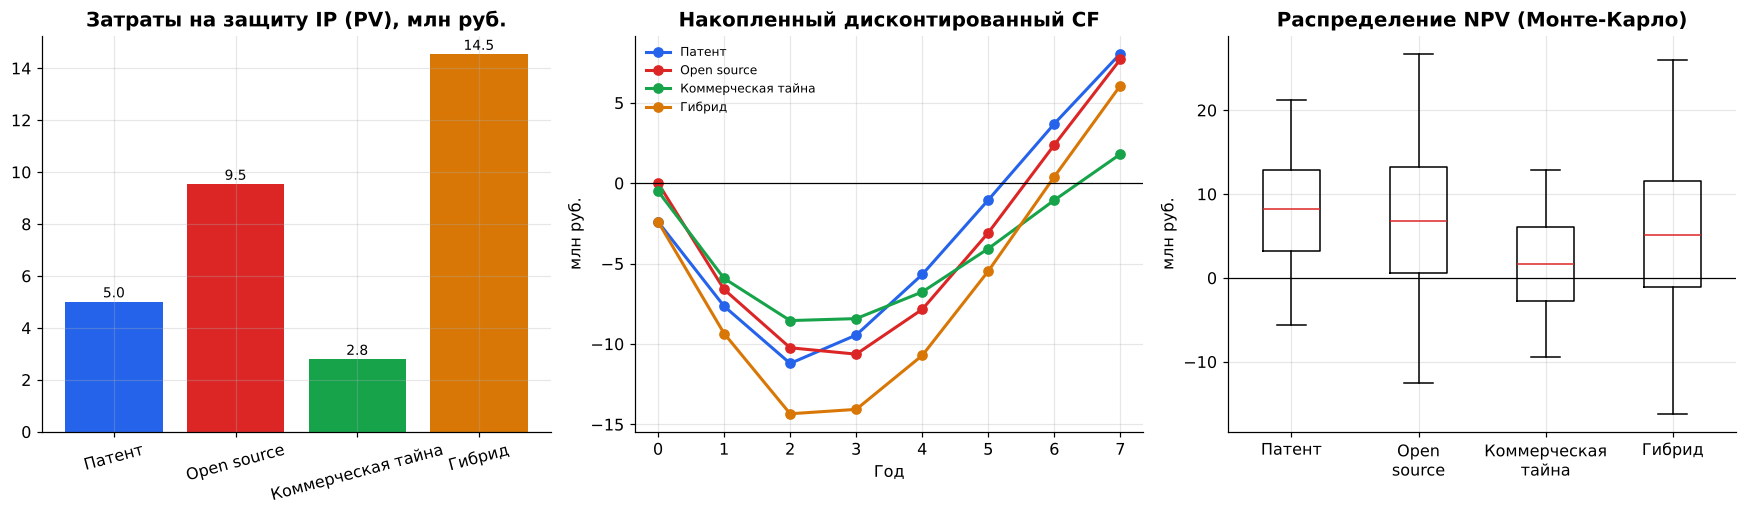

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
ax = axes[0]
bars = ax.bar(strategies, summary_cost["Затраты на IP (PV), млн"], color=PALETTE[:4]); bar_labels(ax, bars, "{:.1f}")
ax.set_title("Затраты на защиту IP (PV), млн руб."); ax.tick_params(axis="x", rotation=15)
ax = axes[1]
for st in strategies:
    ax.plot(flows.index, present_values(flows[st].values, r).cumsum(), "o-", lw=2, label=st)
ax.axhline(0, color="black", lw=0.8); ax.set_xlabel("Год"); ax.set_ylabel("млн руб."); ax.set_title("Накопленный дисконтированный CF")
ax.legend(fontsize=8)
ax = axes[2]
ax.boxplot([mc[s] for s in strategies], tick_labels=[s.replace(" ", "\n") for s in strategies], showfliers=False)
ax.axhline(0, color="black", lw=0.8); ax.set_title("Распределение NPV (Монте-Карло)"); ax.set_ylabel("млн руб.")
plt.tight_layout(); plt.show()

## 6. Интерпретация результатов

- **Затраты на защиту.** Дешевле всего коммерческая тайна (около 2,8 млн руб. PV), патент около 5 млн руб. с учётом
  возможного спора, open source около 9,5 млн руб. на сообщество, дороже всех гибрид (около 14,5 млн руб.):
  он платит и за патент, и за сообщество. Но решают не затраты на защиту, а выручка и экономия на разработке.
- **NPV.** Патент (около 8,1 млн руб.) и open source (около 7,7 млн руб.) почти равны, гибрид около 6,1 млн руб.,
  коммерческая тайна заметно хуже (около 1,8 млн руб.) из-за высокого риска, что алгоритм скопируют.
  Патент выигрывает за счёт роялти и более ранней выручки. Open source выигрывает за счёт сетевого эффекта
  (выручка обгоняет закрытый продукт с 4-го года) и экономии на разработке, но эти деньги приходят позже
  и сильнее уменьшаются при ставке 18 %.
- **Риски (Монте-Карло).** Патент лучший примерно в 54 % испытаний, и шанс убытка у него меньше всех (около 9 %).
  Open source лучший в 42 %, но разброс шире (шанс убытка около 23 %, зато выше лучший возможный результат).
  Коммерческая тайна ни разу не оказалась лучшей.
- **Точка переключения:** open source обгоняет патент, если сообщество экономит от 21 % затрат на разработку (в базе 20 %).
  То есть выбор между ними зависит от того, удастся ли собрать живое сообщество разработчиков.

## 7. Выводы и рекомендации

**Выбор: запатентовать ключевое техническое решение** и держать продукт закрытым. Самый большой NPV (около 8 млн руб.)
и самый низкий риск. Open core равноценная замена, если стартап соберёт сообщество, которое экономит от 20 % затрат
на разработку. Коммерческую тайну как основную стратегию не рекомендуем: AI-алгоритмы рекомендаций легко повторить.

1. Подать заявку на изобретение в РФ именно на техническое решение (способ адаптивного построения траектории),
   а не на «алгоритм», иначе высокий риск отказа. Международную заявку PCT подавать, когда появится интерес зарубежных партнёров.
2. Обученные модели и данные об успехах учеников защищать как **коммерческую тайну**: в патенте они не раскрываются.
3. С 3-го года зарабатывать на патенте лицензиями для издательств и EdTech-платформ.
4. Держать open core в запасе: открыть второстепенные части (SDK, плагины для LMS), чтобы получить часть сетевого эффекта
   и не раскрывать ядро.
5. Заложить резерв на патентный спор (6 млн руб.) или застраховать патентные риски.

**Ограничение:** параметры условные (приложения к задаче нет), а разница между патентом и open source в пределах
неопределённости. На реальных данных выбор нужно пересчитать по этой же модели.